In [2]:
import sys
import torch
import os

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("GPU is not enabled. Select Runtime > Change runtime type > T4 GPU.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
%pip install -U bitsandbytes

In [4]:
import torch
import bitsandbytes as bnb

print("PyTorch:", torch.__version__)
print("BitsAndBytes:", bnb.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not detected")

from bitsandbytes.nn import Linear4bit
print("4-bit layer import: SUCCESS")

PyTorch: 2.11.0+cu130
BitsAndBytes: 0.50.2
CUDA available: True
GPU: Tesla T4
4-bit layer import: SUCCESS


In [5]:
import torch
import transformers
import peft
import trl
import bitsandbytes
import datasets

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("Datasets:", datasets.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not detected")

PyTorch: 2.11.0+cu130
Transformers: 4.57.1
PEFT: 0.15.2
TRL: 0.17.0
BitsAndBytes: 0.50.2
Datasets: 3.6.0
CUDA available: True
GPU: Tesla T4


In [6]:
import os
import json
import random
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_DIR = "/content/PS9_QLoRA_Claims"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")
SCRIPTS_DIR = os.path.join(PROJECT_DIR, "scripts")

for folder in [DATA_DIR, OUTPUT_DIR, REPORT_DIR, SCRIPTS_DIR]:
    os.makedirs(folder, exist_ok=True)

random.seed(42)

claim_types = [
    "Medical", "Property Damage", "Vehicle Accident",
    "Fire Damage", "Water Damage"
]
severities = ["Minor", "Moderate", "Severe"]
documentation_options = ["Complete", "Incomplete"]
policy_statuses = ["Active", "Expired"]

rows = []

for i in range(5000):
    claim_type = random.choice(claim_types)
    amount = random.randint(500, 100000)
    severity = random.choice(severities)
    documentation = random.choice(documentation_options)
    policy_status = random.choice(policy_statuses)

    # Transparent synthetic business rules
    if policy_status == "Expired":
        decision = "DENY"
    elif documentation == "Incomplete":
        decision = "PARTIAL_APPROVAL"
    elif severity == "Severe" and amount > 70000:
        decision = "PARTIAL_APPROVAL"
    else:
        decision = "APPROVE"

    narrative = (
        f"Claim type: {claim_type}. Claim amount: {amount}. "
        f"Damage severity: {severity}. Documentation: {documentation}. "
        f"Policy status: {policy_status}."
    )

    rows.append({
        "claim_id": f"CLM-{i+1:05d}",
        "claim_narrative": narrative,
        "decision": decision
    })

df = pd.DataFrame(rows)

# Reproducible train/validation/test split
train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df["decision"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["decision"]
)

df.to_csv(os.path.join(DATA_DIR, "claims_dataset.csv"), index=False)
train_df.to_csv(os.path.join(DATA_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(DATA_DIR, "validation.csv"), index=False)
test_df.to_csv(os.path.join(DATA_DIR, "test.csv"), index=False)

system_prompt = (
    "You are an insurance claims assistant. Assess the provided claim facts "
    "and return exactly one decision: APPROVE, PARTIAL_APPROVAL, or DENY."
)

with open(
    os.path.join(DATA_DIR, "claims_instruction.jsonl"),
    "w",
    encoding="utf-8"
) as f:
    for row in df.to_dict(orient="records"):
        record = {
            "messages": [
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": row["claim_narrative"]},
                {"role": "assistant", "content": row["decision"]}
            ]
        }
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Dataset created successfully!")
print("Total records:", len(df))
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))
print("\nDecision distribution:")
print(df["decision"].value_counts())
print("\nJSONL sample:")
with open(os.path.join(DATA_DIR, "claims_instruction.jsonl"), encoding="utf-8") as f:
    print(f.readline())

Dataset created successfully!
Total records: 5000
Train: 4000 | Validation: 500 | Test: 500

Decision distribution:
decision
DENY                2458
PARTIAL_APPROVAL    1378
APPROVE             1164
Name: count, dtype: int64

JSONL sample:
{"messages": [{"role": "system", "content": "You are an insurance claims assistant. Assess the provided claim facts and return exactly one decision: APPROVE, PARTIAL_APPROVAL, or DENY."}, {"role": "user", "content": "Claim type: Medical. Claim amount: 3778. Damage severity: Severe. Documentation: Incomplete. Policy status: Active."}, {"role": "assistant", "content": "PARTIAL_APPROVAL"}]}



In [7]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from peft import (
    LoraConfig,
    prepare_model_for_kbit_training,
    get_peft_model
)

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# 4-bit NF4 quantization
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quant_config,
    device_map="auto"
)

model.config.use_cache = False
model = prepare_model_for_kbit_training(model)

# Required LoRA target modules
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

print("\nModel:", MODEL_NAME)
print("Quantization: 4-bit NF4")
print("LoRA targets: q_proj, v_proj")
print("CUDA:", torch.cuda.is_available())
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 3),
    "GB"
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093

Model: Qwen/Qwen2.5-0.5B-Instruct
Quantization: 4-bit NF4
LoRA targets: q_proj, v_proj
CUDA: True
GPU memory allocated: 0.682 GB


In [8]:
import os
import json
import time
import torch
from datasets import Dataset
from trl import SFTConfig, SFTTrainer

# Save training outputs in the project folder
TRAIN_OUTPUT = os.path.join(OUTPUT_DIR, "training")
os.makedirs(TRAIN_OUTPUT, exist_ok=True)

def format_example(example):
    return {
        "text": tokenizer.apply_chat_template(
            example["messages"],
            tokenize=False
        )
    }

def dataframe_to_dataset(frame):
    records = []
    for row in frame.to_dict(orient="records"):
        records.append({
            "messages": [
                {
                    "role": "system",
                    "content": system_prompt
                },
                {
                    "role": "user",
                    "content": row["claim_narrative"]
                },
                {
                    "role": "assistant",
                    "content": row["decision"]
                }
            ]
        })

    return Dataset.from_list(records).map(
        format_example,
        remove_columns=["messages"]
    )

train_dataset = dataframe_to_dataset(train_df)
val_dataset = dataframe_to_dataset(val_df)

# Record peak memory for the training report
torch.cuda.reset_peak_memory_stats()
model.config.use_cache = False

training_args = SFTConfig(
    output_dir=TRAIN_OUTPUT,
    max_steps=100,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=25,
    save_strategy="no",
    fp16=True,
    gradient_checkpointing=True,
    optim="adamw_torch",
    max_length=256,
    dataset_text_field="text",
    report_to="none",
    seed=42
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer
)

start_time = time.perf_counter()
train_result = trainer.train()
training_seconds = time.perf_counter() - start_time

# Re-enable caching for inference
model.config.use_cache = True

ADAPTER_DIR = os.path.join(PROJECT_DIR, "models", "qlora_adapter")
os.makedirs(ADAPTER_DIR, exist_ok=True)

trainer.model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

# Save trainer logs
log_path = os.path.join(OUTPUT_DIR, "trainer_log.jsonl")
with open(log_path, "w", encoding="utf-8") as f:
    for entry in trainer.state.log_history:
        f.write(json.dumps(entry) + "\n")

training_summary = {
    "base_model": MODEL_NAME,
    "quantization": "4-bit NF4",
    "lora_targets": ["q_proj", "v_proj"],
    "max_steps": 100,
    "training_seconds": round(training_seconds, 2),
    "training_minutes": round(training_seconds / 60, 2),
    "trainer_reported_training_loss": float(train_result.training_loss),
    "peak_gpu_memory_gb": round(
        torch.cuda.max_memory_allocated() / 1024**3, 3
    ),
    "train_rows": len(train_df),
    "validation_rows": len(val_df),
    "test_rows": len(test_df)
}

with open(
    os.path.join(REPORT_DIR, "training_summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(training_summary, f, indent=2)

print("\nTRAINING COMPLETE")
print(json.dumps(training_summary, indent=2))

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Converting train dataset to ChatML:   0%|          | 0/4000 [00:00<?, ? examples/s]

Adding EOS to train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

...

Tokenizing eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss,Validation Loss
25,1.976500,1.729015
50,0.581100,0.517260
75,0.380700,0.370564
100,0.346600,0.348741



TRAINING COMPLETE
{
  "base_model": "Qwen/Qwen2.5-0.5B-Instruct",
  "quantization": "4-bit NF4",
  "lora_targets": [
    "q_proj",
    "v_proj"
  ],
  "max_steps": 100,
  "training_seconds": 204.94,
  "training_minutes": 3.42,
  "trainer_reported_training_loss": 1.1827615630626678,
  "peak_gpu_memory_gb": 1.636,
  "train_rows": 4000,
  "validation_rows": 500,
  "test_rows": 500
}


In [9]:
import time
import json
import torch
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
from peft import PeftModel
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

LABELS = ["APPROVE", "PARTIAL_APPROVAL", "DENY"]

# Keep the current trained model as the fine-tuned model.
ft_model = model
ft_model.eval()

# Load a separate, unadapted base model for a fair comparison.
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quant_config,
    device_map="auto"
)
base_model.eval()

def predict_claim(active_model, claim):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": claim}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = active_model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    latency = time.perf_counter() - start

    generated = output[0][inputs["input_ids"].shape[1]:]
    text = tokenizer.decode(generated, skip_special_tokens=True).strip()
    normalized = text.upper().replace(" ", "_")

    # Exact label matching, prioritizing the longer label.
    prediction = next(
        (label for label in sorted(LABELS, key=len, reverse=True)
         if label in normalized),
        "UNPARSED"
    )
    return prediction, latency, text

def evaluate_model(active_model, name):
    predictions, latencies, raw_outputs = [], [], []

    for i, claim in enumerate(test_df["claim_narrative"].tolist()):
        pred, latency, raw = predict_claim(active_model, claim)
        predictions.append(pred)
        latencies.append(latency)
        raw_outputs.append(raw)

        if (i + 1) % 100 == 0:
            print(f"{name}: evaluated {i + 1}/500")

    y_true = test_df["decision"].tolist()
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, predictions,
        labels=LABELS,
        average="macro",
        zero_division=0
    )

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
        "average_latency_seconds": sum(latencies) / len(latencies),
        "total_inference_seconds": sum(latencies),
        "unparsed_predictions": predictions.count("UNPARSED")
    }

    return metrics, predictions, latencies, raw_outputs

base_metrics, base_preds, base_latencies, base_raw = evaluate_model(
    base_model, "Base Model"
)

ft_metrics, ft_preds, ft_latencies, ft_raw = evaluate_model(
    ft_model, "QLoRA Model"
)

results_df = pd.DataFrame([base_metrics, ft_metrics])
results_df.to_csv(
    os.path.join(REPORT_DIR, "evaluation_results.csv"),
    index=False
)

details_df = test_df[["claim_narrative", "decision"]].copy()
details_df["base_prediction"] = base_preds
details_df["qlora_prediction"] = ft_preds
details_df["base_raw_output"] = base_raw
details_df["qlora_raw_output"] = ft_raw
details_df.to_csv(
    os.path.join(REPORT_DIR, "prediction_details.csv"),
    index=False
)

with open(
    os.path.join(REPORT_DIR, "classification_reports.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump({
        "base": classification_report(
            test_df["decision"], base_preds,
            labels=LABELS, zero_division=0, output_dict=True
        ),
        "qlora": classification_report(
            test_df["decision"], ft_preds,
            labels=LABELS, zero_division=0, output_dict=True
        )
    }, f, indent=2)

print("\nBASE vs QLoRA RESULTS")
print(results_df.to_string(index=False))
print("\nQLoRA prediction distribution:")
print(pd.Series(ft_preds).value_counts())
print("\nSaved evaluation reports in:", REPORT_DIR)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Base Model: evaluated 100/500
Base Model: evaluated 200/500
Base Model: evaluated 300/500
Base Model: evaluated 400/500
Base Model: evaluated 500/500
QLoRA Model: evaluated 100/500
QLoRA Model: evaluated 200/500
QLoRA Model: evaluated 300/500
QLoRA Model: evaluated 400/500
QLoRA Model: evaluated 500/500

BASE vs QLoRA RESULTS
      model  accuracy  macro_precision  macro_recall  macro_f1  average_latency_seconds  total_inference_seconds  unparsed_predictions
 Base Model     0.834         0.850142      0.875675  0.845304                 0.214819               107.409324                     0
QLoRA Model     0.978         0.971354      0.973236  0.971092                 0.235968               117.983918                     0

QLoRA prediction distribution:
DENY                246
APPROVE             128
PARTIAL_APPROVAL    126
Name: count, dtype: int64

Saved evaluation reports in: /content/PS9_QLoRA_Claims/reports


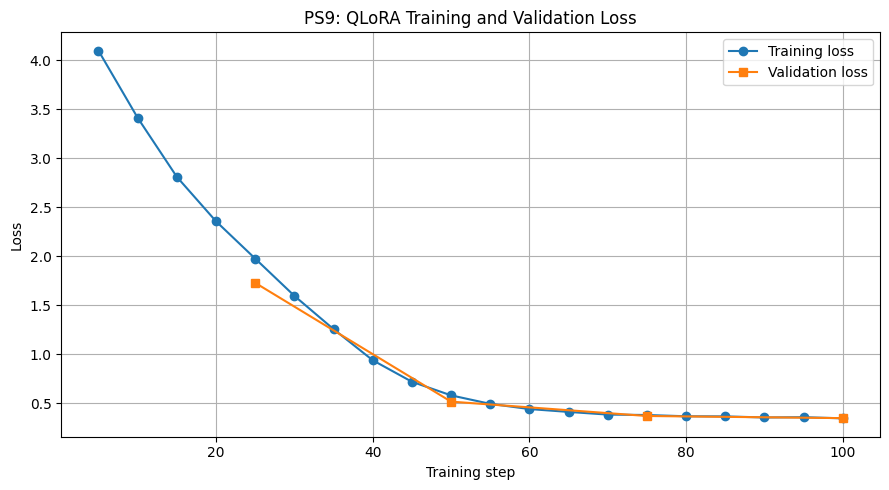

Loss chart saved: /content/PS9_QLoRA_Claims/reports/training_loss_curve.png
Performance report saved.
Final metrics:
      model  accuracy  macro_precision  macro_recall  macro_f1  average_latency_seconds  total_inference_seconds  unparsed_predictions
 Base Model     0.834         0.850142      0.875675  0.845304                 0.214819               107.409324                     0
QLoRA Model     0.978         0.971354      0.973236  0.971092                 0.235968               117.983918                     0


In [10]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# Read the existing training log
log_path = os.path.join(OUTPUT_DIR, "trainer_log.jsonl")
logs = [
    json.loads(line)
    for line in open(log_path, encoding="utf-8")
    if line.strip()
]

loss_steps = [
    item["step"] for item in logs
    if "loss" in item and "eval_loss" not in item
]
train_losses = [
    item["loss"] for item in logs
    if "loss" in item and "eval_loss" not in item
]
eval_steps = [
    item["step"] for item in logs
    if "eval_loss" in item
]
eval_losses = [
    item["eval_loss"] for item in logs
    if "eval_loss" in item
]

plt.figure(figsize=(9, 5))
plt.plot(loss_steps, train_losses, marker="o", label="Training loss")
if eval_losses:
    plt.plot(eval_steps, eval_losses, marker="s", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("PS9: QLoRA Training and Validation Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()

loss_chart = os.path.join(REPORT_DIR, "training_loss_curve.png")
plt.savefig(loss_chart, dpi=160)
plt.show()

# Save a compact performance summary
summary = {
    "base_model": MODEL_NAME,
    "fine_tuning": "4-bit NF4 QLoRA",
    "lora_target_modules": ["q_proj", "v_proj"],
    "dataset_size": len(df),
    "train_size": len(train_df),
    "validation_size": len(val_df),
    "test_size": len(test_df),
    "training_steps": 100,
    "training_minutes": training_summary["training_minutes"],
    "peak_gpu_memory_gb": training_summary["peak_gpu_memory_gb"],
    "trainer_reported_training_loss": training_summary["trainer_reported_training_loss"],
    "base_metrics": base_metrics,
    "qlora_metrics": ft_metrics,
    "loss_curve": loss_chart
}

with open(
    os.path.join(REPORT_DIR, "final_performance_report.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("Loss chart saved:", loss_chart)
print("Performance report saved.")
print("Final metrics:")
print(results_df.to_string(index=False))

In [12]:
from pathlib import Path

PROJECT_DIR = Path("/content/PS9_QLoRA_Claims")

(PROJECT_DIR / "requirements.txt").write_text(
    """torch
transformers==4.57.1
peft==0.15.2
trl==0.17.0
datasets==3.6.0
accelerate==1.7.0
bitsandbytes>=0.50.2
pandas
scikit-learn
matplotlib
""",
    encoding="utf-8"
)

readme = """# PS9 — QLoRA Claims Processing

## Project Overview
Parameter-efficient fine-tuning for insurance claims classification using
4-bit NF4 quantization, LoRA, Hugging Face PEFT, and TRL.

## Dataset
- Total: 5,000 synthetic claim records
- Training: 4,000
- Validation: 500
- Test: 500
- Labels: APPROVE, PARTIAL_APPROVAL, DENY

The dataset is synthetic and rule-generated. It is not real historical
insurance data.

## Model Configuration
- Base model: Qwen/Qwen2.5-0.5B-Instruct
- Quantization: 4-bit NF4 with double quantization
- LoRA targets: q_proj and v_proj
- LoRA rank: 8
- LoRA alpha: 16
- Frameworks: Transformers, PEFT, TRL, BitsAndBytes
- Runtime: Google Colab Tesla T4

The original problem statement requests an 8B model. This implementation uses
a 0.5B model due to GPU memory and runtime constraints.

## Observed Results
- Training steps: 100
- Training duration: approximately 3.42 minutes
- Peak allocated GPU memory: 1.636 GB
- Base accuracy: 83.4%
- QLoRA accuracy: 97.8%
- Base macro F1: 0.8453
- QLoRA macro F1: 0.9711
- Base average latency: approximately 0.215 seconds per claim
- QLoRA average latency: approximately 0.236 seconds per claim

Metrics were measured on 500 synthetic test claims. They demonstrate learning
of synthetic labeling rules, not real-world underwriting performance.

## Project Structure
- data/: CSV dataset, train/validation/test splits, JSONL instructions
- scripts/: reusable training script
- models/qlora_adapter/: trained LoRA adapter
- outputs/: training logs
- reports/: metrics, loss chart, and performance reports
- docs/: implementation notes

## Privacy and Responsible Use
Never use identifiable claim records or PII without authorization. Real-world
deployment requires domain-expert review, representative data, bias analysis,
and regulatory validation.
"""

(PROJECT_DIR / "README.md").write_text(readme, encoding="utf-8")

print("README.md created")
print("requirements.txt created")

README.md created
requirements.txt created


In [13]:
from pathlib import Path

PROJECT_DIR = Path("/content/PS9_QLoRA_Claims")
docs_dir = PROJECT_DIR / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

notes = """# PS9 Implementation Notes

## Methodology
Claims are converted into system, user, and assistant messages. The base
language model is loaded using BitsAndBytes 4-bit NF4 quantization. PEFT
attaches LoRA adapters to q_proj and v_proj. TRL SFTTrainer performs
supervised fine-tuning.

## Evaluation
The base and fine-tuned models were evaluated on the same 500 synthetic test
claims. Accuracy, macro precision, macro recall, macro F1, and average
inference latency were recorded.

## Limitations
1. Synthetic data replaces unavailable historical claims.
2. The implementation uses a 0.5B model rather than the requested 8B model.
3. The test set follows the same generated rules as the training data.
4. Results should not be generalized to real insurance claims.
"""

(docs_dir / "implementation_notes.md").write_text(notes, encoding="utf-8")

print("Implementation documentation created")

Implementation documentation created


In [14]:
import os
import zipfile

PROJECT_DIR = "/content/PS9_QLoRA_Claims"
ZIP_PATH = "/content/PS9_QLoRA_Claims_Complete.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files_list in os.walk(PROJECT_DIR):
        dirs[:] = [
            d for d in dirs
            if d not in {"__pycache__", ".ipynb_checkpoints"}
        ]
        for filename in files_list:
            full_path = os.path.join(root, filename)
            archive_path = os.path.relpath(full_path, "/content")
            zf.write(full_path, archive_path)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    print("ZIP created:", ZIP_PATH)
    print("Files included:", len(zf.namelist()))
    print("ZIP size (MB):", round(os.path.getsize(ZIP_PATH) / 1024**2, 2))
    print("Contains trained adapter:",
          any("qlora_adapter" in name for name in zf.namelist()))

ZIP created: /content/PS9_QLoRA_Claims_Complete.zip
Files included: 25
ZIP size (MB): 5.87
Contains trained adapter: True


In [15]:
from google.colab import files
files.download("/content/PS9_QLoRA_Claims_Complete.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>